# Dynamic Parking Assignment - Deep Q-Network (DQN)

This notebook implements the dynamic parking assignment using **Deep Q-Network (DQN)** with:
- State representation: s = (v, t, A[t], C[t])
- Neural network for Q-value approximation
- Experience replay buffer
- Target network for stable training
- All required search problem functions

## 1. Install and Import Libraries

In [145]:
%pip install numpy pandas matplotlib networkx gymnasium torch torchvision

Note: you may need to restart the kernel to use updated packages.


In [146]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from typing import Dict, List, Tuple, Optional, Set
import random
from collections import defaultdict, deque
from dataclasses import dataclass
import copy

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

import gymnasium as gym 
from gymnasium import spaces 

# Set random seeds
np.random.seed(42)
random.seed(42)
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


## 2. Search State and Problem Definition

In [147]:
@dataclass
class SearchState:
    """State: s = (v, t, A[t], C[t])"""
    v: int  # Current node
    t: float  # Current time
    A_t: Dict[int, int]  # Parking availability
    C_t: Dict[int, float]  # Parking costs
    is_parked: bool = False  # Parked flag
    parked_at: Optional[int] = None  # Parking location
    
    def copy(self):
        return SearchState(
            v=self.v, t=self.t,
            A_t=self.A_t.copy(),
            C_t=self.C_t.copy(),
            is_parked=self.is_parked,
            parked_at=self.parked_at
        )
    
    def __repr__(self):
        return f"State(v={self.v}, t={self.t:.2f}, parked={self.is_parked}, at={self.parked_at})"

## 3. Urban Road Network

Source (S): 0
Destination (D): 14
Parking lots (P): [11, 12, 13]
Parking costs: {11: 7.857431808841254, 12: 7.792606390510127, 13: 19.899779641832133}


/var/folders/d7/2wfht8656x55f3mlkjy6ng0r0000gn/T/ipykernel_4179/3541642025.py:115: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


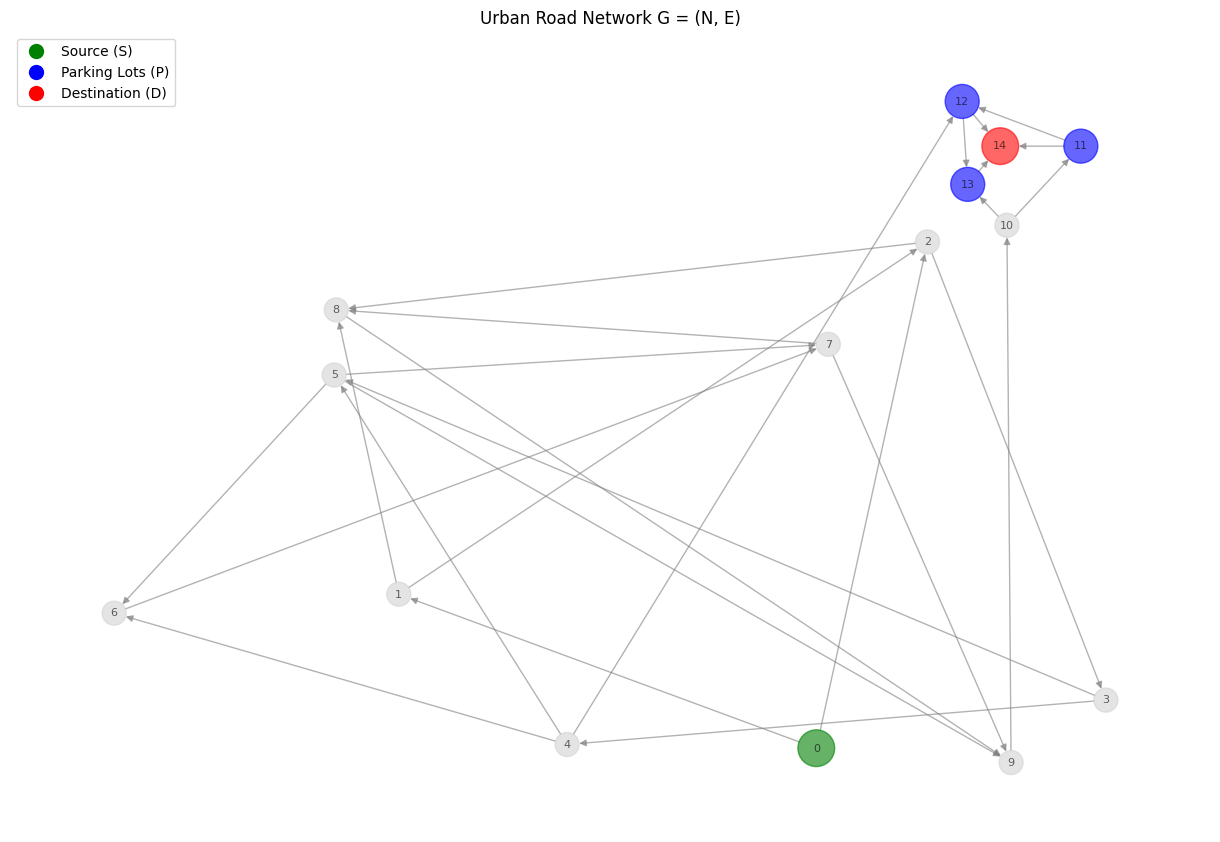

In [148]:
class UrbanRoadNetwork:
    """Directed graph G = (N, E) representing urban road network"""
    
    def __init__(self, num_nodes=15, num_parking_lots=3):
        self.G = nx.DiGraph()
        self.num_nodes = num_nodes
        self.num_parking_lots = num_parking_lots
        
        self.S = 0  # Source
        self.D = num_nodes - 1  # Destination
        self.P = list(range(num_nodes - num_parking_lots - 1, num_nodes - 1))  # Parking lots
        
        self.node_positions = {}
        self._create_network()
        self._assign_initial_travel_times()
        self._assign_base_parking_costs()
        
    def _create_network(self):
        # Add nodes
        for i in range(self.num_nodes):
            self.G.add_node(i)
            self.node_positions[i] = (random.uniform(0, 10), random.uniform(0, 10))
        
        self.node_positions[self.D] = (8, 8)
        
        # Position parking lots around destination
        for i, p_k in enumerate(self.P):
            angle = 2 * np.pi * i / len(self.P)
            radius = random.uniform(0.3, 0.8)
            self.node_positions[p_k] = (
                8 + radius * np.cos(angle),
                8 + radius * np.sin(angle)
            )
        
        # Add edges
        for i in range(self.num_nodes - 1):
            self.G.add_edge(i, i + 1)
            
        for i in range(self.num_nodes - 2):
            if random.random() > 0.6:
                self.G.add_edge(i, i + 2)
                
        for _ in range(self.num_nodes // 3):
            u = random.randint(0, self.num_nodes - 3)
            v = random.randint(u + 1, self.num_nodes - 1)
            if not self.G.has_edge(u, v):
                self.G.add_edge(u, v)
            
        for p_k in self.P:
            if not self.G.has_edge(p_k, self.D):
                self.G.add_edge(p_k, self.D)
            
    def _assign_initial_travel_times(self):
        for u, v in self.G.edges():
            self.G[u][v]['T_base'] = random.uniform(2, 8)
            self.G[u][v]['T_current'] = self.G[u][v]['T_base']
            
    def _assign_base_parking_costs(self):
        self.C_base = {}
        for p_k in self.P:
            self.C_base[p_k] = random.uniform(5, 25)
    
    def get_travel_time(self, u: int, v: int, t: float) -> float:
        if not self.G.has_edge(u, v):
            return float('inf')
        return self.G[u][v]['T_current']
    
    def update_traffic_conditions(self, t: float):
        for u, v in self.G.edges():
            base_time = self.G[u][v]['T_base']
            self.G[u][v]['T_current'] = base_time * random.uniform(0.6, 1.4)
    
    def get_parking_cost(self, p_k: int, t: float) -> float:
        base_cost = self.C_base[p_k]
        variation = 1.0 + 0.2 * np.sin(t / 10)
        return base_cost * variation
    
    def calculate_walking_distance(self, p_k: int, destination: int) -> float:
        pos_pk = self.node_positions[p_k]
        pos_d = self.node_positions[destination]
        return np.sqrt((pos_pk[0] - pos_d[0])**2 + (pos_pk[1] - pos_d[1])**2)
    
    def get_outgoing_edges(self, v: int) -> List[int]:
        return list(self.G.successors(v))
    
    def visualize_network(self):
        plt.figure(figsize=(12, 8))
        pos = self.node_positions
        
        node_colors = []
        node_sizes = []
        for node in self.G.nodes():
            if node == self.S:
                node_colors.append('green')
                node_sizes.append(700)
            elif node == self.D:
                node_colors.append('red')
                node_sizes.append(700)
            elif node in self.P:
                node_colors.append('blue')
                node_sizes.append(600)
            else:
                node_colors.append('lightgray')
                node_sizes.append(300)
                
        nx.draw(self.G, pos, node_color=node_colors, node_size=node_sizes,
                with_labels=True, font_size=8, arrows=True, 
                edge_color='gray', alpha=0.6)
        
        plt.plot([], [], 'o', color='green', markersize=10, label='Source (S)')
        plt.plot([], [], 'o', color='blue', markersize=10, label='Parking Lots (P)')
        plt.plot([], [], 'o', color='red', markersize=10, label='Destination (D)')
        plt.legend(loc='upper left')
        plt.title('Urban Road Network G = (N, E)')
        plt.tight_layout()
        plt.show()

# Create network
network = UrbanRoadNetwork(num_nodes=15, num_parking_lots=3)
print(f"Source (S): {network.S}")
print(f"Destination (D): {network.D}")
print(f"Parking lots (P): {network.P}")
print(f"Parking costs: {network.C_base}")
network.visualize_network()

## 4. Search Problem Functions

In [149]:
def Initial_State(network: UrbanRoadNetwork, t0: float = 0) -> SearchState:
    """s_0 = (S, t_0, A(t_0), C(t_0))"""
    A_t0 = {p_k: np.random.randint(5, 20) for p_k in network.P}
    C_t0 = {p_k: network.get_parking_cost(p_k, t0) for p_k in network.P}
    return SearchState(v=network.S, t=t0, A_t=A_t0, C_t=C_t0)

def Actions(state: SearchState, network: UrbanRoadNetwork) -> List[Tuple[str, int]]:
    """Available actions: drive or park"""
    if state.is_parked:
        return []
    
    actions = []
    for u in network.get_outgoing_edges(state.v):
        actions.append(('drive', u))
    
    if state.v in network.P:
        actions.append(('park', state.v))
    
    return actions

def Transition_Model(state: SearchState, action: Tuple[str, int], 
                    network: UrbanRoadNetwork) -> SearchState:
    """Apply action and return new state"""
    action_type, target = action
    new_state = state.copy()
    
    if action_type == 'drive':
        new_state.v = target
        travel_time = network.get_travel_time(state.v, target, state.t)
        new_state.t = state.t + travel_time
        
        for p_k in network.P:
            change = np.random.randint(-1, 2)
            new_state.A_t[p_k] = max(0, min(20, state.A_t[p_k] + change))
            new_state.C_t[p_k] = network.get_parking_cost(p_k, new_state.t)
        
        if np.random.random() < 0.2:
            network.update_traffic_conditions(new_state.t)
    
    elif action_type == 'park':
        p_k = target
        new_state.is_parked = True
        new_state.parked_at = p_k
        new_state.A_t[p_k] = max(0, new_state.A_t[p_k] - 1)
    
    return new_state

def Goal_Test(state: SearchState, network: UrbanRoadNetwork, W_max: float = 1.0) -> bool:
    """Check if goal is reached: must be parked at valid location"""
    if not state.is_parked:
        return False
    
    p_k = state.parked_at
    if p_k not in network.P or state.A_t[p_k] < 0:
        return False
    
    walking_distance = network.calculate_walking_distance(p_k, network.D)
    return walking_distance <= W_max

def Path_Cost(path: List[SearchState], network: UrbanRoadNetwork, 
             alpha: float = 10.0, beta: float = 1.0) -> float:
    """PathCost = driving_time + α * W(p_k, D) + β * c_k(t)"""
    if len(path) < 2:
        return 0.0
    
    final_state = path[-1]
    initial_state = path[0]
    
    if not final_state.is_parked:
        return float('inf')
    
    driving_time = final_state.t - initial_state.t
    p_k = final_state.parked_at
    walking_distance = network.calculate_walking_distance(p_k, network.D)
    parking_cost = final_state.C_t[p_k]
    
    return driving_time + alpha * walking_distance + beta * parking_cost

print(" Search problem functions defined")

 Search problem functions defined


## 5. Search Problem Class

In [150]:
class ParkingSearchProblem:
    """Complete search problem"""
    
    def __init__(self, network: UrbanRoadNetwork, W_max: float = 1.0, 
                 alpha: float = 10.0, beta: float = 1.0):
        self.network = network
        self.W_max = W_max
        self.alpha = alpha
        self.beta = beta
    
    def initial_state(self) -> SearchState:
        return Initial_State(self.network, t0=0)
    
    def actions(self, state: SearchState) -> List[Tuple[str, int]]:
        return Actions(state, self.network)
    
    def transition(self, state: SearchState, action: Tuple[str, int]) -> SearchState:
        return Transition_Model(state, action, self.network)
    
    def is_goal(self, state: SearchState) -> bool:
        return Goal_Test(state, self.network, self.W_max)
    
    def path_cost(self, path: List[SearchState]) -> float:
        return Path_Cost(path, self.network, self.alpha, self.beta)
    
    def step_cost(self, state: SearchState, action: Tuple[str, int]) -> float:
        action_type, target = action
        
        if action_type == 'drive':
            return self.network.get_travel_time(state.v, target, state.t)
        elif action_type == 'park':
            p_k = target
            walking_distance = self.network.calculate_walking_distance(p_k, self.network.D)
            parking_cost = state.C_t[p_k]
            return self.alpha * walking_distance + self.beta * parking_cost
        
        return 0.0

search_problem = ParkingSearchProblem(network, W_max=1.0, alpha=10.0, beta=1.0)
print("Search problem created")

Search problem created


## 6. Reinforcement Learning Environment


In [151]:
class ParkingAssignmentEnv(gym.Env):
    """RL Environment - ENFORCES parking requirement"""
    
    def __init__(self, search_problem: ParkingSearchProblem):
        super(ParkingAssignmentEnv, self).__init__()
        
        self.problem = search_problem
        self.network = search_problem.network
        
        self.max_actions = 10
        self.action_space = spaces.Discrete(self.max_actions)
        
        obs_dim = 3 + len(self.network.P) * 3
        self.observation_space = spaces.Box(
            low=-100, high=100, shape=(obs_dim,), dtype=np.float32
        )
        
        self.current_state = None
        self.available_actions = None
        
    def reset(self):
        self.current_state = self.problem.initial_state()
        self.available_actions = self.problem.actions(self.current_state)
        return self._get_observation()
    
    def _get_observation(self):
        obs = [
            self.current_state.v / self.network.num_nodes,
            self.current_state.t / 100.0,
            1.0 if self.current_state.is_parked else 0.0
        ]
        
        for p_k in self.network.P:
            walk_dist = self.network.calculate_walking_distance(p_k, self.network.D)
            obs.extend([
                self.current_state.C_t[p_k] / 25.0,
                self.current_state.A_t[p_k] / 20.0,
                walk_dist
            ])
        
        return np.array(obs, dtype=np.float32)
    
    def step(self, action_idx):
        if action_idx >= len(self.available_actions):
            return self._get_observation(), -100, True, {'success': False}
        
        action = self.available_actions[action_idx]
        new_state = self.problem.transition(self.current_state, action)
        
        # Check if goal reached (MUST BE PARKED)
        done = self.problem.is_goal(new_state)
        
        if done:
            # SUCCESS: Parked at valid location
            path = [self.problem.initial_state(), new_state]
            cost = self.problem.path_cost(path)
            reward = -cost  # Minimize cost
            info = {'success': True, 'cost': cost}
        elif action[0] == 'park' and new_state.is_parked:
            # Invalid parking location
            done = True
            reward = -100
            info = {'success': False, 'reason': 'Invalid parking'}
        elif new_state.v == self.network.D and not new_state.is_parked:
            # PREVENTED: Reached destination without parking!
            done = True
            reward = -200
            info = {'success': False, 'reason': 'Destination without parking'}
        else:
            # Normal driving step
            step_cost = self.problem.step_cost(self.current_state, action)
            reward = -step_cost * 0.1
            info = {'success': False}
            
            if new_state.t > 100:
                done = True
                reward = -200
                info = {'success': False, 'reason': 'Timeout'}
        
        self.current_state = new_state
        self.available_actions = self.problem.actions(self.current_state) if not done else []
        
        return self._get_observation(), reward, done, info

env = ParkingAssignmentEnv(search_problem)
print(" Environment created")
print(f"  Action space: {env.action_space}")
print(f"  Observation space: {env.observation_space.shape}")
print(f"\nNetwork structure:")
print(f"  Nodes 0-10: Regular roads")
print(f"  Nodes {network.P}: PARKING LOTS (agent must park here)")
print(f"  Node {network.D}: DESTINATION (can only reach if parked)")

 Environment created
  Action space: Discrete(10)
  Observation space: (12,)

Network structure:
  Nodes 0-10: Regular roads
  Nodes [11, 12, 13]: PARKING LOTS (agent must park here)
  Node 14: DESTINATION (can only reach if parked)


## 7. DQN Implementation

In [152]:
class DQN(nn.Module):
    """Neural network for Q-value approximation"""
    
    def __init__(self, state_size, action_size, hidden_size=128):
        super(DQN, self).__init__()
        self.fc1 = nn.Linear(state_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.fc3 = nn.Linear(hidden_size, action_size)
        
    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

state_size = env.observation_space.shape[0]
action_size = env.action_space.n

test_network = DQN(state_size, action_size).to(device)
print("\n=== DQN Architecture ===")
print(test_network)
print(f"\nInput size: {state_size}")
print(f"Output size: {action_size}")
print(f"Parameters: {sum(p.numel() for p in test_network.parameters())}")


=== DQN Architecture ===
DQN(
  (fc1): Linear(in_features=12, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
)

Input size: 12
Output size: 10
Parameters: 19466


In [153]:
class ReplayBuffer:
    """Experience replay buffer"""
    
    def __init__(self, capacity=10000):
        self.buffer = deque(maxlen=capacity)
    
    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))
    
    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)
        return (
            np.array(states),
            np.array(actions),
            np.array(rewards, dtype=np.float32),
            np.array(next_states),
            np.array(dones, dtype=np.float32)
        )
    
    def __len__(self):
        return len(self.buffer)

print("Replay buffer defined")

Replay buffer defined


In [154]:
class DQNAgent:
    """Deep Q-Network Agent with stability improvements"""
    
    def __init__(self, state_size, action_size, 
                 learning_rate=0.0001,
                 gamma=0.99,
                 epsilon_start=1.0,
                 epsilon_end=0.05,
                 epsilon_decay=0.9995,
                 buffer_size=10000,
                 batch_size=32,
                 target_update_freq=50):
        
        self.state_size = state_size
        self.action_size = action_size
        self.gamma = gamma
        self.epsilon = epsilon_start
        self.epsilon_end = epsilon_end
        self.epsilon_decay = epsilon_decay
        self.batch_size = batch_size
        self.target_update_freq = target_update_freq
        
        self.q_network = DQN(state_size, action_size).to(device)
        self.target_network = DQN(state_size, action_size).to(device)
        self.target_network.load_state_dict(self.q_network.state_dict())
        self.target_network.eval()
        
        self.optimizer = optim.Adam(self.q_network.parameters(), lr=learning_rate)
        self.replay_buffer = ReplayBuffer(buffer_size)
        self.train_step = 0
    
    def select_action(self, state, available_actions_count, training=True):
        if training and random.random() < self.epsilon:
            return random.randint(0, available_actions_count - 1)
        else:
            with torch.no_grad():
                state_tensor = torch.FloatTensor(state).unsqueeze(0).to(device)
                q_values = self.q_network(state_tensor)
                q_values_np = q_values.cpu().numpy()[0]
                valid_q_values = q_values_np[:available_actions_count]
                return np.argmax(valid_q_values)
    
    def store_transition(self, state, action, reward, next_state, done):
        self.replay_buffer.push(state, action, reward, next_state, done)
    
    def train(self):
        if len(self.replay_buffer) < self.batch_size:
            return None
        
        states, actions, rewards, next_states, dones = self.replay_buffer.sample(self.batch_size)
        
        states = torch.FloatTensor(states).to(device)
        actions = torch.LongTensor(actions).to(device)
        rewards = torch.FloatTensor(rewards).to(device)
        next_states = torch.FloatTensor(next_states).to(device)
        dones = torch.FloatTensor(dones).to(device)
        
        current_q_values = self.q_network(states).gather(1, actions.unsqueeze(1)).squeeze(1)
        
        with torch.no_grad():
            next_q_values = self.target_network(next_states).max(1)[0]
            target_q_values = rewards + (1 - dones) * self.gamma * next_q_values
        
        loss = F.mse_loss(current_q_values, target_q_values)
        
        self.optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.q_network.parameters(), max_norm=1.0)
        self.optimizer.step()
        
        self.train_step += 1
        if self.train_step % self.target_update_freq == 0:
            self.target_network.load_state_dict(self.q_network.state_dict())
        
        return loss.item()
    
    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_end, self.epsilon * self.epsilon_decay)

agent = DQNAgent(
    state_size=state_size,
    action_size=action_size,
    learning_rate=0.0001,
    gamma=0.99,
    epsilon_start=1.0,
    epsilon_end=0.05,
    epsilon_decay=0.9995,
    buffer_size=10000,
    batch_size=32,
    target_update_freq=50
)

print("\n=== DQN Agent Created ===")
print(f"Learning rate: 0.0001 (low for stability)")
print(f"Gamma: 0.99 (high discount factor)")
print(f"Batch size: 32")
print(f"Target update frequency: 50")
print(f"Buffer capacity: 10000")


=== DQN Agent Created ===
Learning rate: 0.0001 (low for stability)
Gamma: 0.99 (high discount factor)
Batch size: 32
Target update frequency: 50
Buffer capacity: 10000


## 8. Training

In [155]:
def train_dqn(env, agent, episodes=300, max_steps=30):
    rewards_history = []
    success_history = []
    epsilon_history = []
    loss_history = []
    cost_history = []
    
    print("Starting DQN training...\n")
    print("Improvements:")
    
    for episode in range(episodes):
        state = env.reset()
        total_reward = 0
        episode_losses = []
        
        for step in range(max_steps):
            num_available = len(env.available_actions)
            if num_available == 0:
                break
            
            action = agent.select_action(state, num_available, training=True)
            next_state, reward, done, info = env.step(action)
            
            scaled_reward = reward / 100.0
            agent.store_transition(state, action, scaled_reward, next_state, done)
            
            if len(agent.replay_buffer) > agent.batch_size * 2:
                loss = agent.train()
                if loss is not None:
                    episode_losses.append(min(loss, 10000))
            
            total_reward += reward
            state = next_state
            
            if done:
                break
        
        agent.decay_epsilon()
        
        rewards_history.append(total_reward)
        success_history.append(1 if info.get('success', False) else 0)
        epsilon_history.append(agent.epsilon)
        if episode_losses:
            loss_history.append(np.mean(episode_losses))
        if 'cost' in info:
            cost_history.append(info['cost'])
        
        if len(rewards_history) >= 10:
            avg_reward = np.mean(rewards_history[-10:])
            success_rate = np.mean(success_history[-10:])
        else:
            avg_reward = np.mean(rewards_history)
            success_rate = np.mean(success_history)
        
        avg_loss = np.mean(loss_history[-10:]) if len(loss_history) >= 10 else (np.mean(loss_history) if loss_history else 0)
        
        if (episode + 1) % 20 == 0:
            print(f"Episode {episode+1:3d}/{episodes} | Reward: {avg_reward:7.2f} | Success: {success_rate:5.1%} | Loss: {avg_loss:8.4f} | ε: {agent.epsilon:.4f}")
    
    return rewards_history, success_history, epsilon_history, loss_history, cost_history

print("\n" + "="*80)
print("Training agent")
print("="*80)

rewards, successes, epsilons, losses, costs = train_dqn(env, agent, episodes=1000, max_steps=30)

print("\n" + "="*80)
print("Training complete")
print("="*80)




Training agent
Starting DQN training...

Improvements:
Episode  20/1000 | Reward: -101.66 | Success: 70.0% | Loss:   0.1826 | ε: 0.9900
Episode  40/1000 | Reward: -129.56 | Success: 50.0% | Loss:   0.2162 | ε: 0.9802
Episode  60/1000 | Reward:  -94.58 | Success: 70.0% | Loss:   0.1710 | ε: 0.9704
Episode  80/1000 | Reward: -157.05 | Success: 30.0% | Loss:   0.1831 | ε: 0.9608
Episode 100/1000 | Reward: -162.06 | Success: 30.0% | Loss:   0.1865 | ε: 0.9512
Episode 120/1000 | Reward: -145.06 | Success: 40.0% | Loss:   0.1799 | ε: 0.9418
Episode 140/1000 | Reward: -145.71 | Success: 40.0% | Loss:   0.1773 | ε: 0.9324
Episode 160/1000 | Reward: -101.04 | Success: 70.0% | Loss:   0.1784 | ε: 0.9231
Episode 180/1000 | Reward: -173.07 | Success: 20.0% | Loss:   0.1796 | ε: 0.9139
Episode 200/1000 | Reward: -129.91 | Success: 50.0% | Loss:   0.1881 | ε: 0.9048
Episode 220/1000 | Reward: -101.62 | Success: 70.0% | Loss:   0.1804 | ε: 0.8958
Episode 240/1000 | Reward: -159.62 | Success: 30.0% |

## 9. Visualization

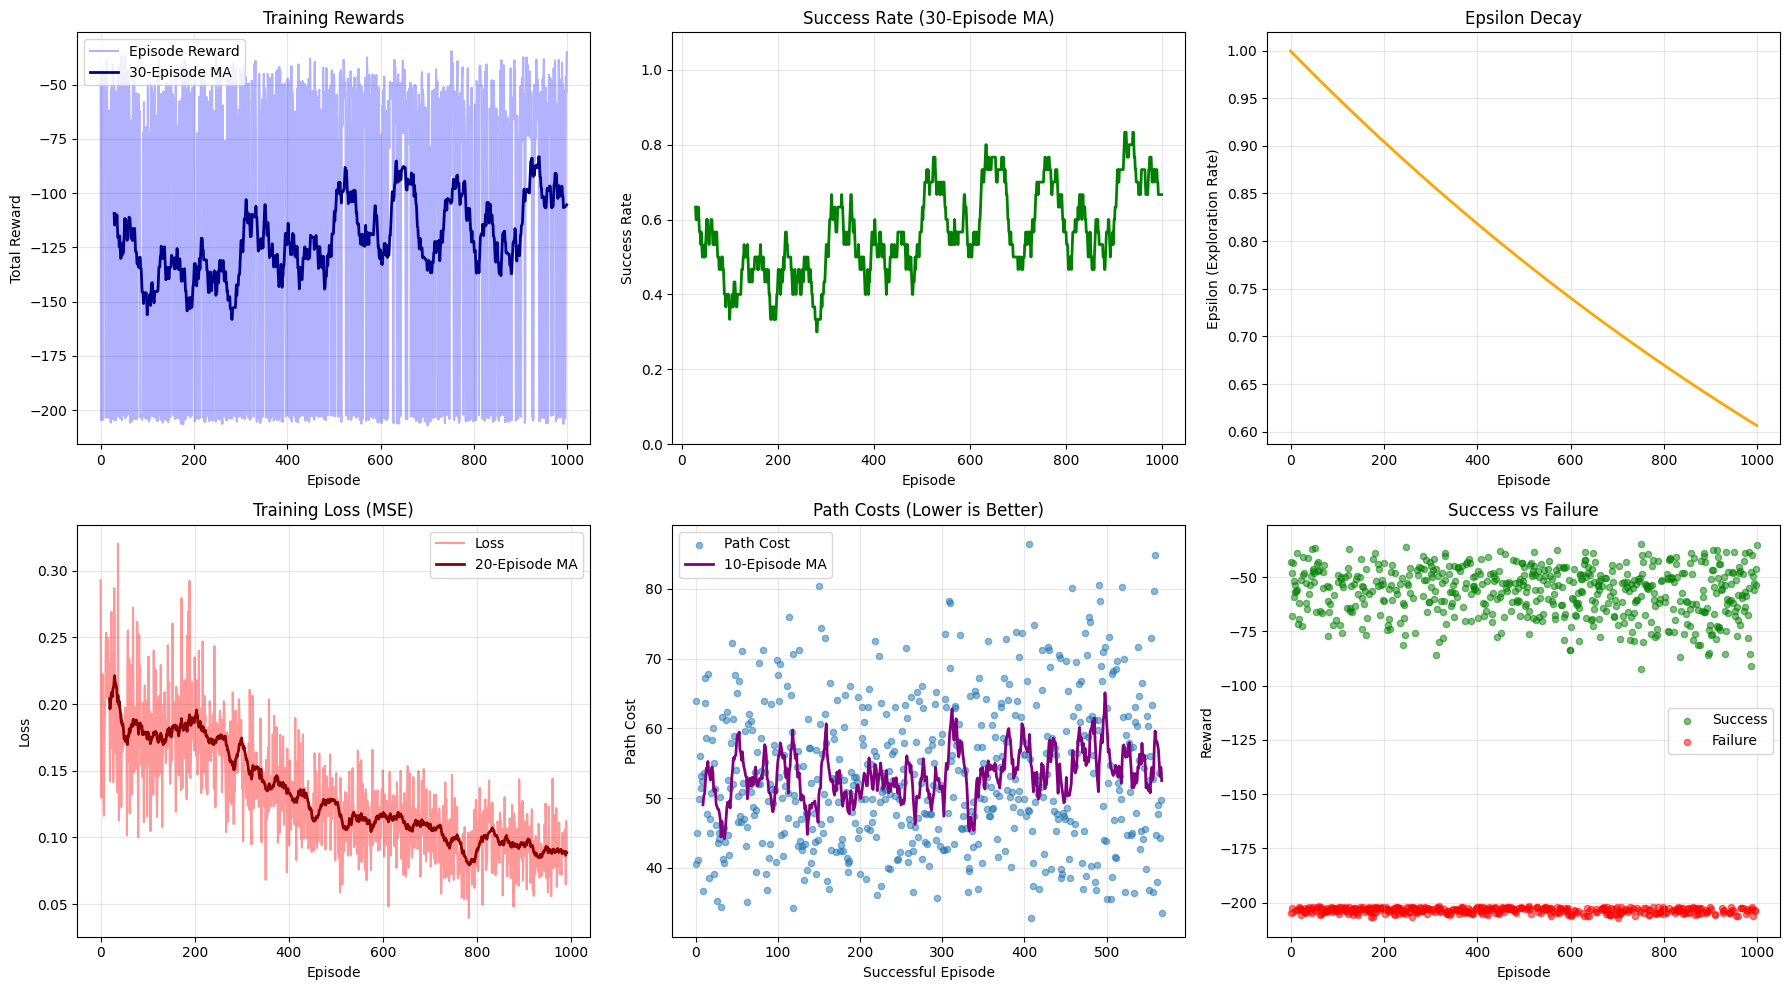

In [156]:
def plot_dqn_results(rewards, successes, epsilons, losses, costs):
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    window = 30
    
    # Rewards
    axes[0, 0].plot(rewards, alpha=0.3, label='Episode Reward', color='blue')
    if len(rewards) >= window:
        moving_avg = np.convolve(rewards, np.ones(window)/window, mode='valid')
        axes[0, 0].plot(range(window-1, len(rewards)), moving_avg, linewidth=2, label=f'{window}-Episode MA', color='darkblue')
    axes[0, 0].set_xlabel('Episode')
    axes[0, 0].set_ylabel('Total Reward')
    axes[0, 0].set_title('Training Rewards')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    # Success Rate
    if len(successes) >= window:
        success_rate = np.convolve(successes, np.ones(window)/window, mode='valid')
        axes[0, 1].plot(range(window-1, len(successes)), success_rate, linewidth=2, color='green')
    axes[0, 1].set_xlabel('Episode')
    axes[0, 1].set_ylabel('Success Rate')
    axes[0, 1].set_title(f'Success Rate ({window}-Episode MA)')
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].set_ylim([0, 1.1])
    
    # Epsilon Decay
    axes[0, 2].plot(epsilons, linewidth=2, color='orange')
    axes[0, 2].set_xlabel('Episode')
    axes[0, 2].set_ylabel('Epsilon (Exploration Rate)')
    axes[0, 2].set_title('Epsilon Decay')
    axes[0, 2].grid(True, alpha=0.3)
    
    # Loss
    if losses:
        axes[1, 0].plot(losses, alpha=0.4, color='red', label='Loss')
        if len(losses) >= 20:
            loss_ma = np.convolve(losses, np.ones(20)/20, mode='valid')
            axes[1, 0].plot(range(19, len(losses)), loss_ma, linewidth=2, color='darkred', label='20-Episode MA')
        axes[1, 0].set_xlabel('Episode')
        axes[1, 0].set_ylabel('Loss')
        axes[1, 0].set_title('Training Loss (MSE)')
        axes[1, 0].legend()
        axes[1, 0].grid(True, alpha=0.3)
    
    # Path Costs
    if costs:
        axes[1, 1].scatter(range(len(costs)), costs, alpha=0.5, s=20, label='Path Cost')
        if len(costs) >= 10:
            cost_ma = np.convolve(costs, np.ones(10)/10, mode='valid')
            axes[1, 1].plot(range(9, len(costs)), cost_ma, linewidth=2, color='purple', label='10-Episode MA')
        axes[1, 1].set_xlabel('Successful Episode')
        axes[1, 1].set_ylabel('Path Cost')
        axes[1, 1].set_title('Path Costs (Lower is Better)')
        axes[1, 1].legend()
        axes[1, 1].grid(True, alpha=0.3)
    
    # Success vs Reward
    successful_episodes = [i for i, s in enumerate(successes) if s == 1]
    failed_episodes = [i for i, s in enumerate(successes) if s == 0]
    
    if successful_episodes:
        axes[1, 2].scatter([i for i in successful_episodes], [rewards[i] for i in successful_episodes],
                          alpha=0.5, s=20, color='green', label='Success')
    if failed_episodes:
        axes[1, 2].scatter([i for i in failed_episodes], [rewards[i] for i in failed_episodes],
                          alpha=0.5, s=20, color='red', label='Failure')
    axes[1, 2].set_xlabel('Episode')
    axes[1, 2].set_ylabel('Reward')
    axes[1, 2].set_title('Success vs Failure')
    axes[1, 2].legend()
    axes[1, 2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

plot_dqn_results(rewards, successes, epsilons, losses, costs)

## 10. Test Trained Agent

In [157]:
def test_dqn_agent(env, agent, num_episodes=10, verbose=True):
    test_results = []
    
    for episode in range(num_episodes):
        state = env.reset()
        done = False
        steps = 0
        total_reward = 0
        
        if verbose:
            print(f"\n{'='*60}")
            print(f"Test Episode {episode + 1}")
            print(f"{'='*60}")
            print(f"Initial state: {env.current_state}")
        
        while not done and steps < 30:
            num_available = len(env.available_actions)
            if num_available == 0:
                break
            
            action_idx = agent.select_action(state, num_available, training=False)
            action = env.available_actions[action_idx]
            
            if verbose:
                print(f"  Step {steps}: {action[0]} to node {action[1]}")
            
            next_state, reward, done, info = env.step(action_idx)
            total_reward += reward
            
            state = next_state
            steps += 1
            
            if done:
                if info.get('success'):
                    cost = info.get('cost', 0)
                    if verbose:
                        print(f"\n   SUCCESS!")
                        print(f"    Parked at: {env.current_state.parked_at}")
                        print(f"    Path cost: {cost:.2f}")
                        print(f"    Steps: {steps}")
                else:
                    if verbose:
                        print(f"\n   FAILED: {info.get('reason', 'Unknown')}")
                
                test_results.append({
                    'success': info.get('success', False),
                    'reward': total_reward,
                    'cost': info.get('cost', None),
                    'steps': steps,
                    'parked_at': env.current_state.parked_at if env.current_state.is_parked else None
                })
    
    # Summary
    print(f"\n{'='*60}")
    print("TEST SUMMARY")
    print(f"{'='*60}")
    
    successes = sum(1 for r in test_results if r['success'])
    print(f"Success rate: {successes}/{num_episodes} ({successes/num_episodes*100:.1f}%)")
    
    successful_tests = [r for r in test_results if r['success']]
    if successful_tests:
        avg_reward = np.mean([r['reward'] for r in successful_tests])
        avg_cost = np.mean([r['cost'] for r in successful_tests])
        avg_steps = np.mean([r['steps'] for r in successful_tests])
        print(f"Average reward: {avg_reward:.2f}")
        print(f"Average path cost: {avg_cost:.2f}")
        print(f"Average steps: {avg_steps:.1f}")
        
        parked_locations = [r['parked_at'] for r in successful_tests]
        print(f"Parking locations used: {sorted(set(parked_locations))}")
    
    return test_results

print("\n" + "="*80)
print("Testing trained agent")
print("="*80)

test_results = test_dqn_agent(env, agent, num_episodes=10, verbose=True)


Testing trained agent

Test Episode 1
Initial state: State(v=0, t=0.00, parked=False, at=None)
  Step 0: drive to node 1
  Step 1: drive to node 8
  Step 2: drive to node 9
  Step 3: drive to node 10
  Step 4: drive to node 11
  Step 5: drive to node 12
  Step 6: park to node 12

   SUCCESS!
    Parked at: 12
    Path cost: 42.04
    Steps: 7

Test Episode 2
Initial state: State(v=0, t=0.00, parked=False, at=None)
  Step 0: drive to node 1
  Step 1: drive to node 2
  Step 2: drive to node 3
  Step 3: drive to node 4
  Step 4: drive to node 5
  Step 5: drive to node 6
  Step 6: drive to node 7
  Step 7: drive to node 8
  Step 8: drive to node 9
  Step 9: drive to node 10
  Step 10: drive to node 11
  Step 11: drive to node 12
  Step 12: park to node 12

   SUCCESS!
    Parked at: 12
    Path cost: 69.69
    Steps: 13

Test Episode 3
Initial state: State(v=0, t=0.00, parked=False, at=None)
  Step 0: drive to node 1
  Step 1: drive to node 8
  Step 2: drive to node 9
  Step 3: drive to n

## 11. Save/Load Model

In [158]:
def save_dqn_model(agent, filepath='dqn_parking_model.pth'):
    torch.save({
        'q_network_state_dict': agent.q_network.state_dict(),
        'target_network_state_dict': agent.target_network.state_dict(),
        'optimizer_state_dict': agent.optimizer.state_dict(),
        'epsilon': agent.epsilon,
        'train_step': agent.train_step
    }, filepath)
    print(f"Model saved to {filepath}")

def load_dqn_model(agent, filepath='dqn_parking_model.pth'):
    checkpoint = torch.load(filepath)
    agent.q_network.load_state_dict(checkpoint['q_network_state_dict'])
    agent.target_network.load_state_dict(checkpoint['target_network_state_dict'])
    agent.optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    agent.epsilon = checkpoint['epsilon']
    agent.train_step = checkpoint['train_step']
    print(f"Model loaded from {filepath}")

# save_dqn_model(agent, 'dqn_parking_model.pth')
# load_dqn_model(agent, 'dqn_parking_model.pth')

print(" Save/Load functions available")

 Save/Load functions available



### 10. Summary of Search Problem Components

### Implemented Functions:

1. **State Representation**: s = (v, t, A[t], C[t])
   - v: current vehicle position
   - t: current time
   - A[t]: parking availability
   - C[t]: parking costs

2. **Initial_State(network, t0)**: s₀ = (S, t₀, A(t₀), C(t₀))

3. **Actions(state, network)**:
   - Navigate: drive along edge ⟨v, u⟩
   - Park: commit to parking lot pₖ

4. **Transition_Model(state, action, network)**:
   - Updates position and time
   - Updates availability and costs
   - Handles dynamic conditions

5. **Goal_Test(state, network, W_max)**:
   - Vehicle parked at pₖ
   - Aₖ(t) > 0
   - W(pₖ, D) ≤ W_max

6. **Path_Cost(path, network, α, β)**:
   - PathCost = driving_time + α·W(pₖ, D) + β·cₖ(t)

### Next Steps:
- Experiment with different α and β values
- Try different network configurations
- Implement more sophisticated search algorithms (A*, Dijkstra)
- Add real-world constraints (traffic lights, one-way streets)